#Driver Distraction Detection


Mounting Google Drive in Google Colab allows you to access and interact with files stored in your Google Drive directly from your Colab notebook. This is useful for accessing datasets, saving trained models, or working with any other files stored in your Google Drive. It provides a convenient way to leverage the storage and collaboration capabilities of Google Drive within the Colab environment

In [ ]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


# Dataset Collection

In [ ]:
# Read the kaggle API token to interact with your kaggle account
from google.colab import files
files.upload()
# Series of commands to set-up for download
!ls -lha kaggle.json
!pip install -q kaggle # installing the kaggle package
!mkdir -p ~/.kaggle # creating .kaggle folder where the key should be placed
!cp kaggle.json ~/.kaggle/ # move the key to the folder
!pwd # checking the present working directory

# giving rw access (if 401-nathorized)
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json
-rw-r--r-- 1 root root 64 Jan 30 13:28 kaggle.json
/content


The first command downloads the dataset "state-farm-distracted-driver-detection" from Kaggle using the Kaggle API.

The second command unzips the downloaded dataset file into the current directory, allowing access to its contents for further exploration and analysis.

In [ ]:
import os
# create a new folder for  Driver_Distraction_Detection
if not os.path.exists("/content/gdrive/MyDrive/Driver_Distraction_Detection/"):
    os.mkdir("/content/gdrive/MyDrive/Driver_Distraction_Detection/")


In [ ]:
# Download data command
!kaggle competitions download -c state-farm-distracted-driver-detection

# move dataset into created folder
!mv /content/state-farm-distracted-driver-detection.zip /content/gdrive/MyDrive/Driver_Distraction_Detection

100% 3.99G/4.00G [00:49<00:00, 166MB/s]
100% 4.00G/4.00G [00:49<00:00, 86.4MB/s]


The below code snippet first checks if the directory "/content/gdrive/MyDrive/Driver_Distraction_Detection" exists. If it doesn't, it creates the directory. It then checks if the directory "/content/gdrive/MyDrive/Driver_Distraction_Detection" exists, and if not, it creates it. Finally, it moves the "Driver_Distraction_Detection" directory (containing the dataset) to "/content/gdrive/MyDrive/Driver_Distraction_Detection", ensuring the dataset is organized within the project directory for better management and access.

After moving sucessfully dataset on google drive then don't run the cell becuase of getting some error

In [ ]:
!unzip /content/gdrive/MyDrive/Driver_Distraction_Detection/state-farm-distracted-driver-detection.zip -d .

Streaming output truncated to the last 5000 lines.
  inflating: ./imgs/train/c7/img_56661.jpg  
  inflating: ./imgs/train/c7/img_56699.jpg  
  inflating: ./imgs/train/c7/img_56717.jpg  
  inflating: ./imgs/train/c7/img_56724.jpg  
  inflating: ./imgs/train/c7/img_56768.jpg  
  inflating: ./imgs/train/c7/img_56779.jpg  
  inflating: ./imgs/train/c7/img_56849.jpg  
  inflating: ./imgs/train/c7/img_56899.jpg  
  inflating: ./imgs/train/c7/img_56938.jpg  
  inflating: ./imgs/train/c7/img_5706.jpg  
  inflating: ./imgs/train/c7/img_57076.jpg  
  inflating: ./imgs/train/c7/img_57122.jpg  
  inflating: ./imgs/train/c7/img_57137.jpg  
  inflating: ./imgs/train/c7/img_5715.jpg  
  inflating: ./imgs/train/c7/img_57278.jpg  
  inflating: ./imgs/train/c7/img_57321.jpg  
  inflating: ./imgs/train/c7/img_57345.jpg  
  inflating: ./imgs/train/c7/img_57355.jpg  
  inflating: ./imgs/train/c7/img_5741.jpg  
  inflating: ./imgs/train/c7/img_57433.jpg  
  inflating: ./imgs/train/c7/img_5753.jpg  
  inflat

In [ ]:
from imutils import paths
import random
import matplotlib.pyplot as plt
import os
from PIL import Image
import cv2
import numpy as np
from tensorflow.keras.utils import img_to_array

# Visualization

In [ ]:
# Get all image paths from the folder
imagePaths = list(paths.list_images("/content/imgs/train"))
# Function to display a grid of images
classnames = {"c0":"normal driving",
"c1": "texting - right",
"c2": "talking on the phone - right",
"c3":" texting - left",
"c4": "talking on the phone - left",
"c5": "operating the radio",
"c6": "drinking",
"c7": "reaching behind",
"c8": "hair and makeup",
"c9": "talking to passenger"}
def display_images(image_paths, title, cols=5, num_images=25):  # Set cols and add num_images
    random.shuffle(image_paths)  # Shuffle the image paths randomly
    num_images = min(len(image_paths), num_images)  # Limit the number of images to display
    rows = (num_images + cols - 1) // cols

    plt.figure(figsize=(12, 12))  # Adjust figure size to accommodate more rows
    plt.suptitle(title)

    for i, image_path in enumerate(image_paths[:num_images]):
        plt.subplot(rows, cols, i + 1)
        img = Image.open(image_path)
        plt.imshow(img,cmap = "gray")
        label = classnames.get(os.path.basename(os.path.dirname(image_path)))
        plt.title(label)
        plt.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Display a random set of images in a 5x5 grid
display_images(imagePaths, title="Random Sample of Images from Different Classes", num_images=25)


# Dataset Preprocessing

In [ ]:
import os
import random
import matplotlib.pyplot as plt

# Folder containing all classes
data_folder = "/content/imgs/train"

# Number of images needed for train and validation
train_count = 500
val_count = 100

# Dictionary to store train and validation paths
train_paths = {cls: [] for cls in os.listdir(data_folder)}
val_paths = {cls: [] for cls in os.listdir(data_folder)}

# Iterate through each class folder
for cls in train_paths.keys():
    class_folder = os.path.join(data_folder, cls)
    if os.path.isdir(class_folder):
        # Get all image paths in the class folder
        images = [os.path.join(class_folder, img) for img in os.listdir(class_folder) if img.endswith(('.png', '.jpg', '.jpeg'))]
        # Shuffle the images to randomize the selection
        random.shuffle(images)
        # Split into train and validation
        train_paths[cls] = images[:train_count]
        val_paths[cls] = images[train_count:train_count + val_count]

# Count images per class for train and validation
train_counts = {cls: len(paths) for cls, paths in train_paths.items()}
val_counts = {cls: len(paths) for cls, paths in val_paths.items()}

# Visualization: Bar plot for training image counts
plt.figure(figsize=(10, 6))
plt.bar(train_counts.keys(), train_counts.values(), color='green', alpha=0.7)
plt.xlabel("Class Names", fontsize=12)
plt.ylabel("Number of Training Images", fontsize=12)
plt.title("Number of Training Images Per Class", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

# Visualization: Bar plot for validation image counts
plt.figure(figsize=(10, 6))
plt.bar(val_counts.keys(), val_counts.values(), color='blue', alpha=0.7)
plt.xlabel("Class Names", fontsize=12)
plt.ylabel("Number of Validation Images", fontsize=12)
plt.title("Number of Validation Images Per Class", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
import cv2
import os
import numpy as np
class SimpleDatasetLoader:
	def __init__(self, preprocessors=None):
		# store the image preprocessor
		self.preprocessors = preprocessors

		# if the preprocessors are None, initialize them as an
		# empty list
		if self.preprocessors is None:
			self.preprocessors = []

	def load(self, imagePaths, verbose=-1):
		# initialize the list of features and labels
		data = []
		labels = []

		# loop over the input images
		for (i, imagePath) in enumerate(imagePaths):
			# load the image and extract the class label assuming
			# that our path has the following format:
			# /path/to/dataset/{class}/{image}.jpg
			image = cv2.imread(imagePath)
			label = imagePath.split(os.path.sep)[-2]

			# check to see if our preprocessors are not None
			if self.preprocessors is not None:
				# loop over the preprocessors and apply each to
				# the image
				for p in self.preprocessors:
					image = p.preprocess(image)

			# treat our processed image as a "feature vector"
			# by updating the data list followed by the labels
			data.append(image)
			labels.append(label)

			# show an update every `verbose` images
			if verbose > 0 and i > 0 and (i + 1) % verbose == 0:
				print("[INFO] processed {}/{}".format(i + 1,
					len(imagePaths)))

		# return a tuple of the data and labels
		return (np.array(data), np.array(labels))

In [ ]:
import cv2
class SimplePreprocessor:
	def __init__(self, width, height, inter=cv2.INTER_AREA):
		# store the target image width, height, and interpolation
		# method used when resizing
		self.width = width
		self.height = height
		self.inter = inter

	def preprocess(self, image):
		# resize the image to a fixed size, ignoring the aspect
		# ratio
		return cv2.resize(image, (self.width, self.height),
			interpolation=self.inter)

In [ ]:
from tensorflow.keras.preprocessing.image import img_to_array
class ImageToArrayPreprocessor:
	def __init__(self, dataFormat=None):
		# store the image data format
		self.dataFormat = dataFormat

	def preprocess(self, image):
		# apply the Keras utility function that correctly rearranges
		# the dimensions of the image
		return img_to_array(image, data_format=self.dataFormat)

In [ ]:
# initialize the image preprocessors
sp = SimplePreprocessor(128,128)
iap = ImageToArrayPreprocessor()

In [ ]:
# Combine all training image paths into a single list
all_train_paths = [path for paths in train_paths.values() for path in paths]

# Combine all validation image paths into a single list (optional)
all_val_paths = [path for paths in val_paths.values() for path in paths]

# Output the size of the lists
print(f"Total training images: {len(all_train_paths)}")
print(f"Total validation images: {len(all_val_paths)}")


Total training images: 5000
Total validation images: 1000


The execution may take some time to complete due to the large number of images, exceeding 2700 in this case

In [ ]:
# load the dataset
sdl = SimpleDatasetLoader(preprocessors=[sp,iap])
(train_data, train_labels) = sdl.load(all_train_paths, verbose=1000)

[INFO] processed 1000/5000
[INFO] processed 2000/5000
[INFO] processed 3000/5000
[INFO] processed 4000/5000
[INFO] processed 5000/5000


In [ ]:
# load the dataset
sdl = SimpleDatasetLoader(preprocessors=[sp,iap])
(val_data, val_labels) = sdl.load(all_val_paths, verbose=500)

[INFO] processed 500/1000
[INFO] processed 1000/1000


# Image Normalization

In [ ]:
# Data Normalization for all train and validatoin all image
train_scaled_data = train_data.astype('float32')/255
val_scaled_data = val_data.astype('float32')/255

In [ ]:
# Since the dataloader function takes some time to complete, we can store it in the npy file format for tim taken and don't execute again dataloader function
# np.save("/content/gdrive/MyDrive/Driver_Distraction_Detection/train_scaled_data.npy",train_scaled_data)
# np.save("/content/gdrive/MyDrive/Driver_Distraction_Detection/train_labels.npy",train_labels)
# np.save("/content/gdrive/MyDrive/Driver_Distraction_Detection/val_scaled_data.npy",val_scaled_data)
# np.save("/content/gdrive/MyDrive/Driver_Distraction_Detection/val_labels.npy",val_labels)

In [ ]:
# load the saved in npy format
import numpy as np
train_scaled_data = np.load("/content/gdrive/MyDrive/Driver_Distraction_Detection/train_scaled_data.npy")
train_labels = np.load("/content/gdrive/MyDrive/Driver_Distraction_Detection/train_labels.npy")
val_scaled_data = np.load("/content/gdrive/MyDrive/Driver_Distraction_Detection/val_scaled_data.npy")
val_labels = np.load("/content/gdrive/MyDrive/Driver_Distraction_Detection/val_labels.npy")

In [ ]:
print('train_scaled_data',train_scaled_data.shape,'val_scaled_data',val_scaled_data.shape,'train_labels',train_labels.shape,'val_labels',val_labels.shape)

train_scaled_data (5000, 128, 128, 3) val_scaled_data (1000, 128, 128, 3) train_labels (5000,) val_labels (1000,)


In [ ]:
import pandas as pd
train_val_data = {'total data':[len(train_scaled_data),len(val_scaled_data),len(train_labels),len(val_labels)]}
pd.DataFrame.from_dict(train_val_data, orient='index',columns=["train_scaled_data","train_labels","val_scaled_data","val_labels"])

,train_scaled_data,train_labels,val_scaled_data,val_labels
total data,5000,1000,5000,1000


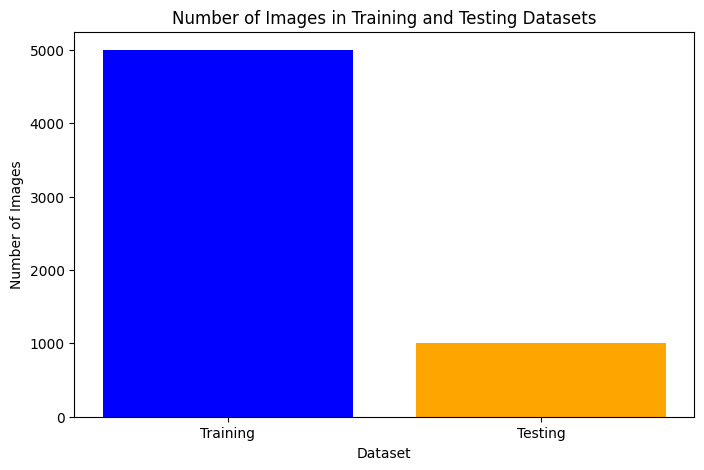

In [ ]:
# Calculate the number of images for training and testing
import matplotlib.pyplot as plt
num_train_images = len(train_scaled_data)
num_test_images = len(val_scaled_data)
# Create a bar plot
plt.figure(figsize=(8, 5))
plt.bar(['Training', 'Testing'], [num_train_images, num_test_images], color=['blue', 'orange'])
plt.xlabel('Dataset')
plt.ylabel('Number of Images')
plt.title('Number of Images in Training and Testing Datasets')
plt.show()


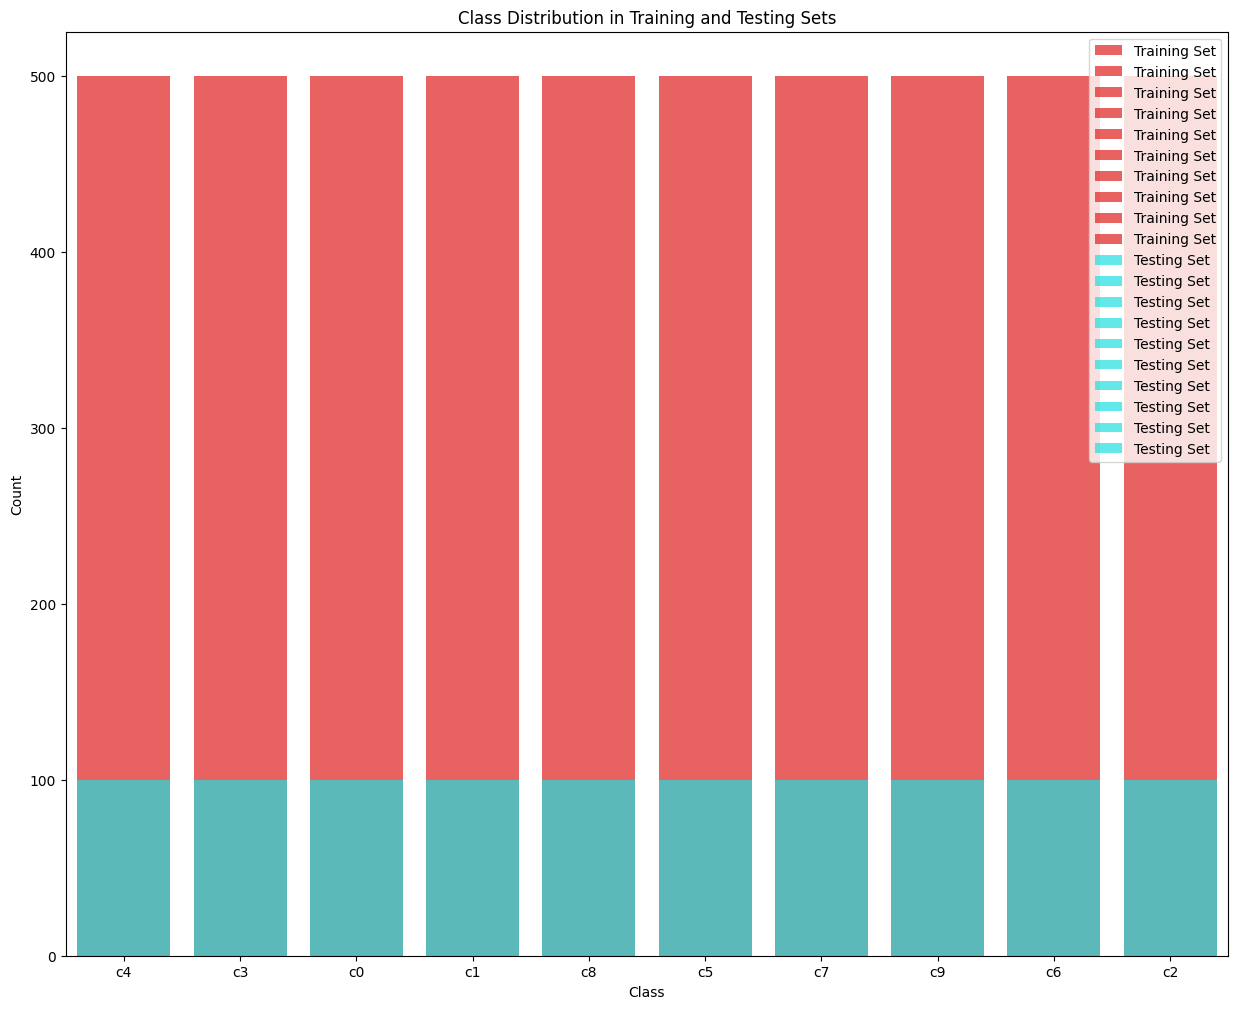

In [ ]:
# Convert y_train and y_test back to DataFrames
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
train_data = pd.DataFrame({'Class': train_labels})
test_data = pd.DataFrame({'Class': val_labels})

train_color = ["red"]
test_color = ["cyan"]

# Create a bar plot to visualize the class distribution in the training and testing sets
plt.figure(figsize=(15, 12))
sns.countplot(x='Class', data=train_data, palette=train_color, alpha=0.7, label='Training Set',legend=False)
sns.countplot(x='Class', data=test_data, palette=test_color, alpha=0.7, label='Testing Set',legend=False)
plt.title('Class Distribution in Training and Testing Sets')
plt.xlabel('Class')
plt.ylabel('Count')
plt.legend()
plt.show()


# Apply to_categorical for Target Output

LabelBinarizer converts integer class labels into binary class matrices suitable for deep learning models, ensuring compatibility and enabling the use of categorical cross-entropy loss.
One-hot encoding facilitates clearer interpretation of model predictions, simplifies loss calculation, and enables the computation of evaluation metrics in classification tasks

In [ ]:
# convert the labels from integers to vectors
from sklearn.preprocessing import LabelBinarizer
y_train_label = LabelBinarizer().fit_transform(train_labels)
y_test_label = LabelBinarizer().fit_transform(val_labels)


# Training using ResNet-50 Algorithm

In [ ]:

import os
import h5py
import math
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model, load_model
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Add, Dense, Activation, ZeroPadding2D, BatchNormalization, Flatten, Conv2D, AveragePooling2D, MaxPooling2D, GlobalMaxPooling2D
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.imagenet_utils import preprocess_input
from IPython.display import SVG
from tensorflow.keras.utils import plot_model
from tensorflow.keras.initializers import glorot_uniform
import scipy.misc
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
from tensorflow.keras.optimizers import Adam
%matplotlib inline
import tensorflow.keras.backend as K
# Image dataset has channels as its last dimensions
K.set_image_data_format('channels_last')
TF_USE_LEGACY_KERAS=True

In [ ]:
def identity_block(X, f, filters, stage, block):

  '''
  Implementation of identity block described above

  Arguments:
  X -       input tensor to the block of shape (m, n_H_prev, n_W_prev, n_C_prev)
  f -       defines shpae of filter in the middle layer of the main path
  filters - list of integers, defining the number of filters in each layer of the main path
  stage -   defines the block position in the network
  block -   used for naming convention

  Returns:
  X - output is a tensor of shape (n_H, n_W, n_C) which matches (m, n_H_prev, n_W_prev, n_C_prev)
  '''

  # defining base name for block
  conv_base_name = 'res' + str(stage) + block + '_'
  bn_base_name = 'bn' + str(stage) + block + '_'

  # retrieve number of filters in each layer of main path
  # NOTE: f3 must be equal to n_C. That way dimensions of the third component will match the dimension of original input to identity block
  f1, f2, f3 = filters

  # Batch normalization must be performed on the 'channels' axis for input. It is 3, for our case
  bn_axis = 3

  # save input for "addition" to last layer output; step in skip-connection
  X_skip_connection = X

  # ----------------------------------------------------------------------
  # Building layers/component of identity block using Keras functional API

  # First component/layer of main path
  X = Conv2D(filters= f1, kernel_size = (1,1), strides = (1,1), padding='valid', name=conv_base_name+'first_component', kernel_initializer = glorot_uniform(seed=0))(X)
  X = BatchNormalization(axis=bn_axis, name=bn_base_name+'first_component')(X)
  X = Activation('relu')(X)

  # Second component/layer of main path
  X = Conv2D(filters= f2, kernel_size = (f,f), strides = (1,1), padding='same', name=conv_base_name+'second_component', kernel_initializer = glorot_uniform(seed=0))(X)
  X = BatchNormalization(axis=bn_axis, name=bn_base_name+'second_component')(X)
  X = Activation('relu')(X)

  # Third component/layer of main path
  X = Conv2D(filters= f3, kernel_size = (1,1), strides = (1,1), padding='valid', name=conv_base_name+'third_component', kernel_initializer = glorot_uniform(seed=0))(X)
  X = BatchNormalization(axis=bn_axis, name=bn_base_name+'third_component')(X)

  # "Addition step" - skip-connection value merges with main path
  # NOTE: both values have same dimensions at this point, so no operation is required to match dimensions
  X = Add()([X, X_skip_connection])
  X = Activation('relu')(X)

  return X

In [ ]:
def convolutional_block(X, f, filters, stage, block, s = 2):
    """
    Implementation of the convolutional block as defined in above figure

    Arguments:
    X -       input tensor to the block of shape (m, n_H_prev, n_W_prev, n_C_prev)
    f -       defines shape of filter in the middle layer of the main path
    filters - list of integers, defining the number of filters in each layer of the main path
    stage -   defines the block position in the network
    block -   used for naming convention
    s -       specifies the stride to be used

    Returns:
    X -- output of the convolutional block, tensor of shape (n_H, n_W, n_C)
    """

    # defining base name for block
    conv_base_name = 'res' + str(stage) + block + '_'
    bn_base_name = 'bn' + str(stage) + block + '_'

    # retrieve number of filters in each layer of main path
    f1, f2, f3 = filters

    # Batch normalization must be performed on the 'channels' axis for input. It is 3, for our case
    bn_axis = 3

    # save input for "addition" to last layer output; step in skip-connection
    X_skip_connection = X

    ##### MAIN PATH #####
    # First component of main path
    X = Conv2D(f1, (1, 1), strides = (s,s), padding = 'valid', name = conv_base_name + 'first_component', kernel_initializer = glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis = bn_axis, name = bn_base_name + 'first_component')(X)
    X = Activation('relu')(X)

    # Second component of main path
    X = Conv2D(f2,  kernel_size = (f, f), strides = (1,1), padding = 'same', name = conv_base_name + 'second_component', kernel_initializer = glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis = bn_axis, name = bn_base_name + 'second_component')(X)
    X = Activation('relu')(X)

    # Third component of main path
    X = Conv2D(f3, kernel_size = (1, 1), strides = (1,1), padding = 'valid', name = conv_base_name + 'third_component', kernel_initializer = glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis = bn_axis, name = bn_base_name + 'third_component')(X)

    ##### Convolve skip-connection value to match its dimensions to third layer output's dimensions ####
    X_skip_connection = Conv2D(f3, (1, 1), strides = (s,s), padding = 'valid', name = conv_base_name + 'merge', kernel_initializer = glorot_uniform(seed=0))(X_skip_connection)
    X_skip_connection = BatchNormalization(axis = 3, name = bn_base_name + 'merge')(X_skip_connection)

    # "Addition step"
    # NOTE: both values have same dimensions at this point
    X = Add()([X, X_skip_connection])
    X = Activation('relu')(X)

    return X

In [ ]:
def ResNet50(input_shape,classes ):
    """
    Arguments:
    input_shape - shape of the images of the dataset
    classes - number of classes

    Returns:
    model - a Model() instance in Keras

    """

    # plug in input_shape to define the input tensor
    X_input = Input(input_shape)

    # Zero-Padding : pads the input with a pad of (3,3)
    X = ZeroPadding2D((3, 3))(X_input)

    # Stage 1
    X = Conv2D(64, (7, 7), strides = (2, 2), name = 'conv_1', kernel_initializer = glorot_uniform(seed=0))(X)
    X = BatchNormalization(axis = 3, name = 'bn_1')(X)
    X = Activation('relu')(X)
    X = MaxPooling2D((3, 3), strides=(2, 2))(X)

    # NOTE: dimensions of filters that are passed to identity block are such that final layer output
    # in identity block mathces the original input to the block
    # blocks in each stage are alphabetically sequenced

    # Stage 2
    X = convolutional_block(X, f = 3, filters = [64, 64, 256], stage = 2, block='a', s = 1)
    X = identity_block(X, 3, [64, 64, 256], stage=2, block='b')
    X = identity_block(X, 3, [64, 64, 256], stage=2, block='c')

    # Stage 3
    X = convolutional_block(X, f=3, filters=[128, 128, 512], stage=3, block='a', s=2)
    X = identity_block(X, 3, [128, 128, 512], stage=3, block='b')
    X = identity_block(X, 3, [128, 128, 512], stage=3, block='c')
    X = identity_block(X, 3, [128, 128, 512], stage=3, block='d')

    # Stage 4
    X = convolutional_block(X, f=3, filters=[256, 256, 1024], stage=4, block='a', s=2)
    X = identity_block(X, 3, [256, 256, 1024], stage=4, block='b')
    X = identity_block(X, 3, [256, 256, 1024], stage=4, block='c')
    X = identity_block(X, 3, [256, 256, 1024], stage=4, block='d')
    X = identity_block(X, 3, [256, 256, 1024], stage=4, block='e')
    X = identity_block(X, 3, [256, 256, 1024], stage=4, block='f')

    # Stage 5
    X = convolutional_block(X, f=3, filters=[512, 512, 2048], stage=5, block='a', s=2)
    X = identity_block(X, 3, [512, 512, 2048], stage=5, block='b')
    X = identity_block(X, 3, [512, 512, 2048], stage=5, block='c')

    # Average Pooling
    X = AveragePooling2D((2, 2), name='avg_pool')(X)

    # output layer
    X = Flatten()(X)
    X = Dense(512, activation='relu', kernel_initializer=glorot_uniform(seed=0))(X)
    X = Dense(256, activation='relu', kernel_initializer=glorot_uniform(seed=0))(X)
    X = Dense(128, activation='relu', kernel_initializer=glorot_uniform(seed=0))(X)
    X = Dense(64, activation='relu', kernel_initializer=glorot_uniform(seed=0))(X)
    X = Dense(classes, activation='softmax', name='fc' + str(classes), kernel_initializer=glorot_uniform(seed=0))(X)
    # Create model
    model = Model(inputs = X_input, outputs = X, name='ResNet50')

    return model

In [ ]:

model = ResNet50(input_shape = (128,128, 3), classes = 10)
model.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 128, 128, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d            │ (None, 134, 134, 3)    │              0 │ input_layer[0][0]      │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv_1 (Conv2D)           │ (None, 64, 64, 64)     │          9,472 │ zero_padding2d[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn_1 (BatchNormalization) │ (None, 64, 64, 64)     │            256 │ conv_1[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 64, 64, 64)     │              0 │ bn_1[0][0]             │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 31, 31, 64)     │              0 │ activation[0][0]       │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ res2a_first_component     │ (None, 31, 31, 64)     │          4,160 │ max_pooling2d[0][0]    │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn2a_first_component      │ (None, 31, 31, 64)     │            256 │ res2a_first_component… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 31, 31, 64)     │              0 │ bn2a_first_component[… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ res2a_second_component    │ (None, 31, 31, 64)     │         36,928 │ activation_1[0][0]     │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn2a_second_component     │ (None, 31, 31, 64)     │            256 │ res2a_second_componen… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 31, 31, 64)     │              0 │ bn2a_second_component… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ res2a_third_component     │ (None, 31, 31, 256)    │         16,640 │ activation_2[0][0]     │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ res2a_merge (Conv2D)      │ (None, 31, 31, 256)    │         16,640 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn2a_third_component      │ (None, 31, 31, 256)    │          1,024 │ res2a_third_component… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ bn2a_merge           

 Total params: 27,955,658 (106.64 MB)

 Trainable params: 27,902,538 (106.44 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint
import pickle

# Define the checkpoint callback
checkpoint = ModelCheckpoint(
    filepath='/content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5',  # Filepath to save the best weights
    monitor='val_accuracy',                     # Metric to monitor
    save_best_only=True,                    # Save only the best weights
    save_weights_only=True,                 # Save only weights, not the full model
    mode='max',                             # 'min' for validation loss
    verbose=1                               # Print messages when saving
)

# Train the model with the checkpoint callback
history = model.fit(
    train_scaled_data,
    y_train_label,
    batch_size=16,
    epochs=10,                                # You can set more epochs
    validation_data=(val_scaled_data, y_test_label),
    callbacks=[checkpoint]                    # Add the callback here
)


# Save the training history separately
with open('/content/gdrive/MyDrive/Driver_Distraction_Detection/resnet_50.pkl', 'wb') as file:
    pickle.dump(history.history, file)


print("resnet-50 classification model trained, and best weights saved!")

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.1006 - loss: 3.0662
Epoch 1: val_accuracy improved from -inf to 0.14300, saving model to /content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 121s 185ms/step - accuracy: 0.1006 - loss: 3.0645 - val_accuracy: 0.1430 - val_loss: 2.4379
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.2509 - loss: 1.9238
Epoch 2: val_accuracy improved from 0.14300 to 0.35800, saving model to /content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 128ms/step - accuracy: 0.2511 - loss: 1.9231 - val_accuracy: 0.3580 - val_loss: 2.2118
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.4876 - loss: 1.3126
Epoch 3: val_accuracy improved from 0.35800 to 0.48500, saving model to /content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 121ms/step - accuracy: 0.4

# Classification Report

In [ ]:
# evaluate the network on the fine-tuned model
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report
# Load the weights
model.load_weights('/content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5')
print("Model weights loaded successfully!")

print("[INFO] evaluating after fine-tuning...")
predictions = model.predict(val_scaled_data, batch_size=16)
classNames = names = [
    "safe driving",
    "texting - right",
    "talking on the phone - right",
    "texting - left",
    "talking on the phone - left",
    "operating the radio",
    "drinking",
    "reaching behind",
    "hair and makeup",
    "talking to passenger"
]

print(classification_report(y_test_label.argmax(axis=1),
	predictions.argmax(axis=1), target_names=classNames))

Model weights loaded successfully!
[INFO] evaluating after fine-tuning...
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 102ms/step
                              precision    recall  f1-score   support

                safe driving       0.72      0.93      0.81       100
             texting - right       0.98      0.91      0.94       100
talking on the phone - right       0.96      0.92      0.94       100
              texting - left       1.00      0.99      0.99       100
 talking on the phone - left       0.87      0.97      0.92       100
         operating the radio       1.00      0.99      0.99       100
                    drinking       0.93      0.98      0.96       100
             reaching behind       0.99      0.93      0.96       100
             hair and makeup       0.89      0.84      0.87       100
        talking to passenger       0.94      0.74      0.83       100

                    accuracy                           0.92      1000
                   macro avg       0.93   

# Confusion matrix

Confusion Matrix:


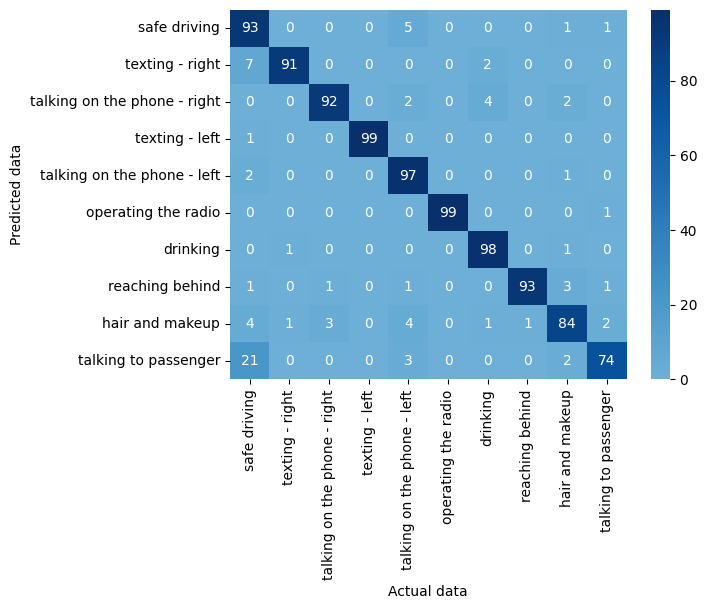

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
print("Confusion Matrix:")
classNames  = [
    "safe driving",
    "texting - right",
    "talking on the phone - right",
    "texting - left",
    "talking on the phone - left",
    "operating the radio",
    "drinking",
    "reaching behind",
    "hair and makeup",
    "talking to passenger"
]

CM = confusion_matrix(y_test_label.argmax(axis=1),
	predictions.argmax(axis=1))
# drawing confusion matrix
sns.heatmap(CM, center = True , annot=True, fmt="d" ,cmap="Blues", xticklabels=classNames, yticklabels=classNames)
plt.xlabel("Actual data")
plt.ylabel("Predicted data")
plt.show()

# Training and validation loss

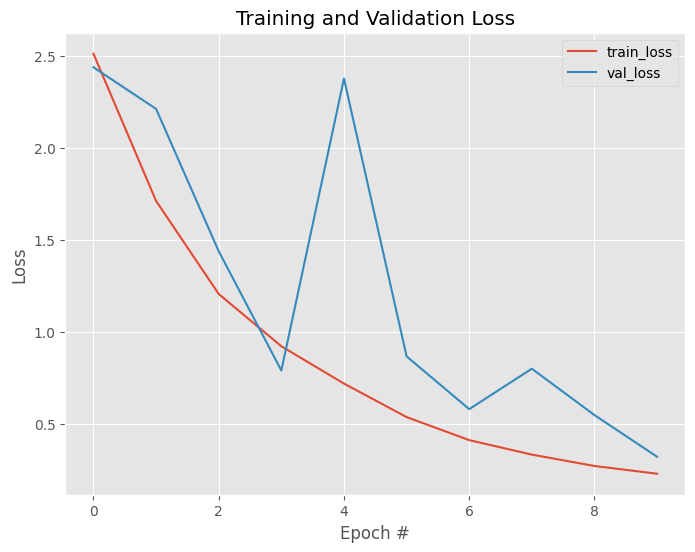

In [ ]:
import pickle
# Load the processed dataset
pickle_file_path = '/content/gdrive/MyDrive/Driver_Distraction_Detection/resnet_50.pkl'
with open(pickle_file_path, 'rb') as file:
    history = pickle.load(file)
plt.style.use("ggplot")
plt.figure(figsize=(8,6))
plt.plot(np.arange(0, len(history["loss"])),history["loss"], label="train_loss")
plt.plot(np.arange(0, len(history["val_loss"])), history["val_loss"], label="val_loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend()
# plt.savefig("output.png")
plt.show()

# Training and validation accuracy

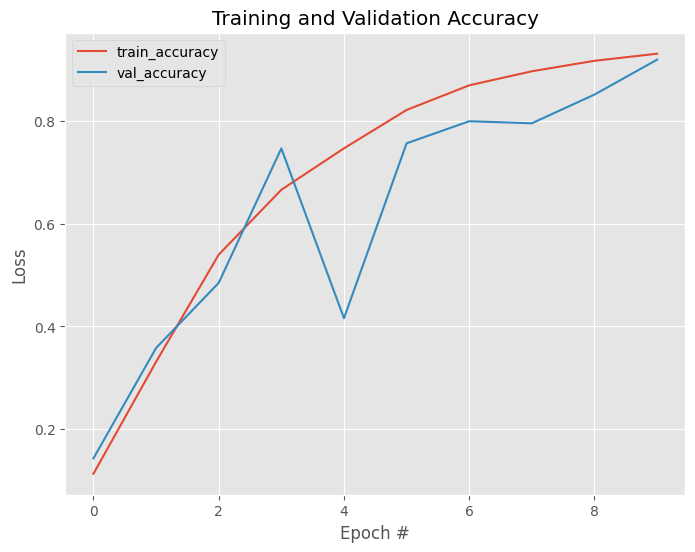

In [ ]:
plt.style.use("ggplot")
plt.figure(figsize=(8,6))
plt.plot(np.arange(0, len(history["accuracy"])), history["accuracy"], label="train_accuracy")
plt.plot(np.arange(0, len(history["val_accuracy"])), history["val_accuracy"], label="val_accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend()
# plt.savefig("output.png")
plt.show()

# 	Prediction and Inference

In [ ]:
import cv2
class SimplePreprocessor:
	def __init__(self, width, height, inter=cv2.INTER_AREA):
		# store the target image width, height, and interpolation
		# method used when resizing
		self.width = width
		self.height = height
		self.inter = inter

	def preprocess(self, image):
		# resize the image to a fixed size, ignoring the aspect
		# ratio
		return cv2.resize(image, (self.width, self.height),
			interpolation=self.inter)

In [ ]:
# initialize the image preprocessors
sp = SimplePreprocessor(128,128)

for getting output from trained modle you need give model file and random input image where you can get from /content/gdrive/MyDrive/Alzheimer_Classification folder

In [ ]:
# Load the weights
model.load_weights('/content/gdrive/MyDrive/Driver_Distraction_Detection/restnet_50.weights.h5')
print("Model weights loaded successfully!")

Model weights loaded successfully!


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 446 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


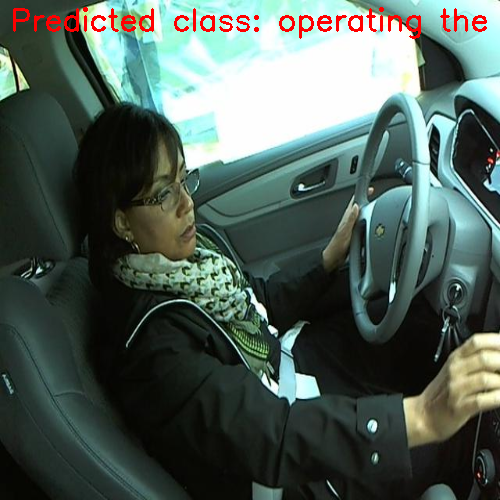

In [ ]:
from google.colab.patches import cv2_imshow
import cv2
import numpy as np
# Load the image
image_path = "/content/imgs/test/img_1.jpg"
image = cv2.imread(image_path)
# Preprocess the image
sp = SimplePreprocessor(128,128)
data =  sp.preprocess(image)
data = data.astype("float") / 255.0
data = np.expand_dims(data, axis=0)

# Predict using the model
prediction = model.predict(data)
Name   = [
    "safe driving",
    "texting - right",
    "talking on the phone - right",
    "texting - left",
    "talking on the phone - left",
    "operating the radio",
    "drinking",
    "reaching behind",
    "hair and makeup",
    "talking to passenger"
]
predicted_class = Name[prediction.argmax()]

# Add text to the image
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 1
font_thickness = 2
text_color = (0,0,255)  # Green color
text = f"Predicted class: {predicted_class}"
text_size = cv2.getTextSize(text, font, font_scale, font_thickness)[0]
resize_img = cv2.resize(image,(500,500))
cv2.putText(resize_img, text, (10,30), font, font_scale, text_color, font_thickness)
# Display the annotated image
cv2_imshow(resize_img)


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Define the video output parameters
# output_video_path = "/content/phone.mp4"
frame_width = 500  # Set the width for the output video
frame_height = 500  # Set the height for the output video
fps = 20  # Frames per second (adjust as needed)

# Initialize the VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'XVID')  # Define codec (XVID)
# out = cv2.VideoWriter(output_video_path, fourcc, fps, (frame_width, frame_height))

# Names for classification
Name = [
    "safe driving",
    "texting - right",
    "talking on the phone - right",
    "texting - left",
    "talking on the phone - left",
    "operating the radio",
    "drinking",
    "reaching behind",
    "hair and makeup",
    "talking to passenger"
]

# Initialize camera
cap = cv2.VideoCapture("/content/Input Video 2.mp4")
# Main loop
while True:
    success, frame = cap.read()
    if not success or frame is None:
        print("Warning: Empty or invalid frame. Skipping...")
        break

    # Preprocess the image
    sp = SimplePreprocessor(128, 128)
    data = sp.preprocess(frame)
    data = data.astype("float") / 255.0
    data = np.expand_dims(data, axis=0)

    # Predict using the model
    prediction = model.predict(data)
    predicted_class = Name[prediction.argmax()]
    print("predicted_class",predicted_class)

    # Add text to the image
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1
    font_thickness = 2
    text_color = (0, 0, 255)  # Red color for text
    text = f"Predicted class: {predicted_class}"
    text_size = cv2.getTextSize(text, font, font_scale, font_thickness)[0]

    # Resize the image
    # resize_img = cv2.resize(frame, (frame_width, frame_height))

    # Put the text on the image
    cv2.putText(frame, text, (10, 30), font, font_scale, text_color, font_thickness)
    # out.write(frame)

    # cv2_imshow(resize_img)
# Optionally, display the video file path
# print(f"Video saved to: {output_video_path}")
# out.release()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
predicted_class safe driving
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted_class hair and makeup
1/1 ━━━━━━━━━━━━━